**15.071 The AI Edge** · Project 1: Predictive AI · Fall 2026 · MIT Sloan School of Management

Team: Audrey DeVault, Paul Bustarret, Charles Loriot, Sara Alafifi

---

# Reading the opposition record: a text-only model of which projects get built

## Background

The tabular notebook (`01_charles_tabular_models.ipynb`) predicts whether a queue project is **operating within 5 years** from what a spreadsheet records: size, technology, grid operator and track records. Local opposition doesn't show up in any of those columns: residents packing a county board meeting, a moratorium, a lawsuit over farmland. It shows up in **text**.

Our text source is the Sabin Center for Climate Change Law's annual report *Opposition to Renewable Energy Facilities in the United States*. Its "contested projects" sections contain one paragraph per project that drew local opposition. Each paragraph names the project and the county, says what residents objected to, and says what happened. We parsed **572 paragraphs** (`queue_risk.sabin`) and labeled every one for its **outcome** and the **concerns** raised (`docs/labeling_guidelines.md`).

**This notebook uses the text alone.** A later step combines it with the tabular model (**late fusion**: each model scores a project on its own, then the two scores are combined). For that, the text model has to score the same thing the tabular model scores, **one queue project**. A Sabin paragraph, though, describes a *different* project: an earlier contested one in the same county. So the model has two stages:

| Stage | Input → output | Course material |
|---|---|---|
| **1. The reader** | one paragraph → P(the contested project **proceeded**) vs. blocked or delayed | Lecture 10 (TF-IDF, beat the easy baseline), 11 (transformers, imbalance), 12 (frozen vs. fine-tuned BERT, per-class recall), 9 (validation set and early stopping) |
| **2. County history → queue project** | the paragraphs about a county's *earlier* contested projects → P(a new project there is built within 5 years) | Lecture 8 (lags built from the past only), 7 (out-of-fold scores feed the next stage), 4 (LASSO) |

Stage 2's out-of-fold scores are written to `data/processed/text_scores.csv`, which is the input to the fusion step.

**Compliance.** The paragraphs are the report's text. They stay out of git (the CSVs are gitignored), and no cell in this notebook prints them unless you flip the `SHOW_TEXT` switch. Clear that cell's output before committing.

## Setup

This notebook is meant for **Google Colab with a GPU** (Runtime → Change runtime type → T4 GPU). The first cell clones the repo and installs the package, as `tabpfn_colab.ipynb` does. It needs a `GITHUB_TOKEN` in Colab Secrets (🔑 in the sidebar). Run locally, the cell is skipped.

On a machine without a GPU, the notebook switches to **quick mode**: shorter inputs, fewer epochs and one seed. The code paths are the same, but the transformer numbers then don't count.

In [1]:
import os, sys, subprocess

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import userdata
    if not os.path.exists("/content/queue-risk-ai"):
        token = userdata.get("GITHUB_TOKEN")
        subprocess.run(["git", "clone", "-q", f"https://{token}@github.com/devault-settings/queue-risk-ai.git",
                        "/content/queue-risk-ai"], check=True)
    os.chdir("/content/queue-risk-ai")
    subprocess.run(["git", "pull", "-q"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", "."], check=True)

In [2]:
import time, warnings
from pathlib import Path

# The project root is the folder holding pyproject.toml, found by walking up
# from wherever this notebook is opened.
ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
print("Project folder:", ROOT)

Project folder: /content/queue-risk-ai


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import Markdown, display
from transformers import (AutoModel, AutoModelForSequenceClassification, AutoTokenizer,
                          get_linear_schedule_with_warmup)
from transformers.utils import logging as hf_logging

from sklearn.decomposition import PCA
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import cohen_kappa_score, f1_score, recall_score, roc_auc_score
from sklearn.model_selection import GridSearchCV, KFold, StratifiedKFold, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from queue_risk import config, data, sabin, text
from queue_risk.stack import bootstrap_gain

hf_logging.set_verbosity_error()
pd.set_option("display.precision", 3)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
FIG = config.FIGURES
FIG.mkdir(parents=True, exist_ok=True)

We fix the random seed for the whole notebook, then pick the device. **Quick mode** turns on automatically when there's no GPU.

In [4]:
SEED = config.SEED
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
QUICK = DEVICE == "cpu"
MAX_LEN = 128 if QUICK else 512     # tokens per paragraph (DistilBERT's limit is 512)
EPOCHS = 1 if QUICK else 6          # upper bound; early stopping usually ends sooner
N_SEEDS = 1 if QUICK else 3         # fine-tuning on ~400 paragraphs is noisy, so we average seeds
BERT = "distilbert-base-uncased"
MINILM = "sentence-transformers/all-MiniLM-L6-v2"
print(f"Device: {DEVICE}" + ("  -> QUICK MODE: transformer results are smoke tests only" if QUICK else ""))

Device: cuda


The labeled paragraphs are gitignored, so a fresh Colab clone doesn't have them. Upload `sabin_labels_all.csv` and `sabin_contested.csv` from `data/interim/` when asked. `sabin_labels_human.csv` is optional; it is only used for the agreement check. Locally, the files are already in place and this cell does nothing.

In [5]:
need = [text.LABELS_CSV, text.CONTESTED_CSV]
if IN_COLAB and not all(f.exists() for f in need):
    from google.colab import files
    config.INTERIM.mkdir(parents=True, exist_ok=True)
    for name, content in files.upload().items():
        (config.INTERIM / name).write_bytes(content)
missing = [f.name for f in need if not f.exists()]
print("Missing:", missing) if missing else print("Labeled paragraphs found.")

Saving sabin_contested.csv to sabin_contested.csv
Saving sabin_labels_all.csv to sabin_labels_all.csv
Labeled paragraphs found.


## The labeled paragraphs

`text.load_paragraphs()` joins the labels to the parsed report, which adds each paragraph's county codes. It also dates each paragraph by the earliest and latest years its text mentions. The labeling sheet's text is the **cleaned** version, with the footnote citations that the PDF parser had glued onto many paragraphs removed. That matters for dating: a citation such as "(last visited June 6, 2025)" would otherwise make a 2014 dispute look like it ran to 2025.

In [6]:
paras = text.load_paragraphs()
print(f"{len(paras)} paragraphs, {paras['state'].nunique()} states, "
      f"{(paras['fips_list'] != '').mean():.0%} matched to at least one county")
pd.crosstab(paras["outcome"], paras["source"].str.replace("human_.*", "human", regex=True),
            margins=True, margins_name="total")

572 paragraphs, 48 states, 98% matched to at least one county


source,claude,human,total
outcome,,,
blocked,205,38,243
delayed,87,23,110
proceeded,133,29,162
unresolved,47,10,57
total,472,100,572


**Who labeled what, and can we trust it?**

- Two of us labeled 100 paragraphs. 20 of them were labeled by both of us to check agreement; disputes were settled together.
- Claude labeled the other 472, following the same guidelines. Before that, it labeled the 100 human paragraphs **blind**: it matched the settled human outcome 84% of the time (Cohen's kappa 0.78, from the labeling log).

The agreement between the two humans, recomputed from the sheet:

In [7]:
if text.HUMAN_CSV.exists():
    h = pd.read_csv(text.HUMAN_CSV, encoding="utf-8-sig")
    shared = h[h["group"] == "shared"]
    print(f"Human labelers A vs. B on {len(shared)} shared paragraphs: "
          f"agreement {(shared['A_outcome'] == shared['B_outcome']).mean():.0%}, "
          f"Cohen's kappa {cohen_kappa_score(shared['A_outcome'], shared['B_outcome']):.2f}")
else:
    print("sabin_labels_human.csv not uploaded; skipping the agreement check.")

sabin_labels_human.csv not uploaded; skipping the agreement check.


A kappa of 0.72 for two humans and 0.78 for Claude against the settled human labels clears the 0.6 bar we set in the guidelines. The labels aren't perfect, though: most disagreements are about *delayed* vs. *unresolved*, for example a project still pending after opposition.

**The target.** For the investor, the question is whether opposition **stopped or set back** the project. We use a binary label:

- **1 = proceeded** (approved, under construction or operating, despite the opposition)
- **0 = blocked or delayed**

The 57 *unresolved* paragraphs have no outcome yet, so they're left out of training. They still count in stage 2 as "contested, outcome unknown".

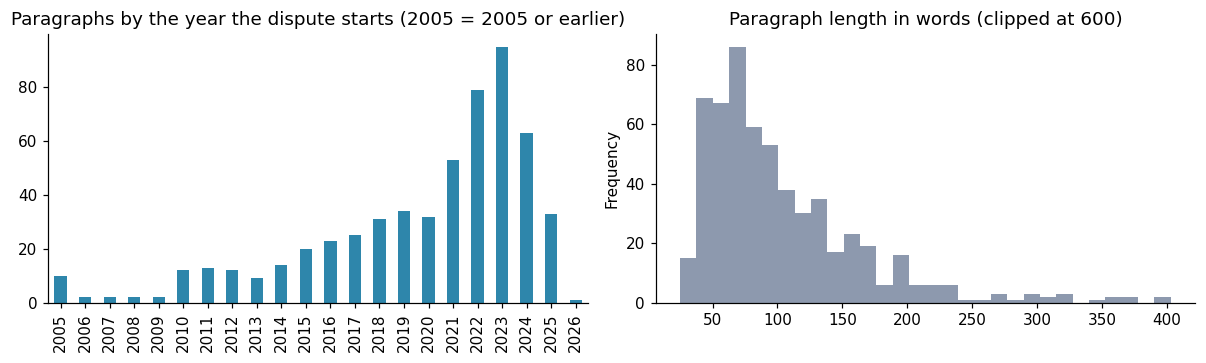

Median length 85 words; 2 run past ~380 words, about DistilBERT's 512-token limit


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
yrs = paras["first_year"].dropna().astype(int)
yrs.clip(lower=2005).value_counts().sort_index().plot.bar(ax=axes[0], color="#2e86ab")
axes[0].set_title("Paragraphs by the year the dispute starts (2005 = 2005 or earlier)")
axes[0].set_xlabel("")
paras["n_words"].clip(upper=600).plot.hist(bins=30, ax=axes[1], color="#8d99ae")
axes[1].set_title("Paragraph length in words (clipped at 600)")
fig.tight_layout()
plt.show()
print(f"Median length {paras['n_words'].median():.0f} words; "
      f"{(paras['n_words'] > 380).sum()} run past ~380 words, about DistilBERT's 512-token limit")

Two facts shape everything below:

1. **The record is recent.** Most disputes start in 2019 or later, since the reports began in 2021 and look back only selectively. Stage 2 can only use paragraphs dated *before* a project's entry, so it has little to say about projects that entered before 2015.
2. **Most paragraphs are short**, but a few run long. When a paragraph has to be cut, we keep the **end**, because the guidelines label the *last* event the paragraph describes.

## Stage 1: the reader

### Train on silver, test on gold

| Set | Paragraphs | Labeled by | Purpose |
|---|---|---|---|
| **Training ("silver")** | Claude's ~425 resolved paragraphs | Claude | Fit and select every reader, with 5-fold cross-validation |
| **Test ("gold")** | the ~90 resolved human-labeled paragraphs | the two of us | Scored **once**, after the reader is chosen |

This split does double duty. It keeps the test set untouched (Lecture 4), and it checks that a reader trained on machine labels still agrees with *human* judgment. A random split wouldn't leak much here, because the paragraphs are about different projects.

In [9]:
R = paras[paras["y"].notna()].copy()
R["y"] = R["y"].astype(int)
silver, gold = R[~R["is_gold"]], R[R["is_gold"]]
pd.DataFrame({"paragraphs": [len(silver), len(gold)],
              "share proceeded": [silver["y"].mean(), gold["y"].mean()]},
             index=["Training (silver, Claude)", "Test (gold, human)"])

,paragraphs,share proceeded
"Training (silver, Claude)",425,0.313
"Test (gold, human)",90,0.322


### How we measure the reader

- **AUC**: does the reader rank proceeded paragraphs above blocked or delayed ones? It's threshold-free, and it's what stage 2 uses, since stage 2 takes the reader's *probability*.
- **Macro-F1** at a 0.5 threshold: the average of the two classes' F1 scores, so the minority class counts as much as the majority.
- **Recall on blocked/delayed** (Lecture 12, per-class recall): of the projects opposition actually stopped or set back, how many the reader catches. For an investor, that's the costly class to miss.

Every reader below is written as a function `fit_predict(train, test) -> P(proceeded)`. The same harness then runs cross-validation, the gold test and the final out-of-fold scoring for every reader, which keeps the comparison fair.

In [10]:
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)


def metrics(y, p):
    y, p = np.asarray(y), np.asarray(p)
    hard = (p >= 0.5).astype(int)
    return {"AUC": roc_auc_score(y, p), "macro-F1": f1_score(y, hard, average="macro"),
            "recall blocked/delayed": recall_score(y, hard, pos_label=0),
            "recall proceeded": recall_score(y, hard, pos_label=1)}


def cross_validate(fit_predict, df=silver):
    """Out-of-fold P(proceeded) for every training paragraph, plus the metrics."""
    oof = pd.Series(np.nan, index=df.index)
    for fit_idx, val_idx in CV.split(df, df["y"]):
        oof.iloc[val_idx] = fit_predict(df.iloc[fit_idx], df.iloc[val_idx])
    return oof, metrics(df["y"], oof)


def boot_auc(y, p, n=2000, seed=SEED):
    """95% bootstrap interval for AUC: with ~90 test paragraphs it is wide."""
    rng, y, p, out = np.random.default_rng(seed), np.asarray(y), np.asarray(p), []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        if y[i].min() != y[i].max():
            out.append(roc_auc_score(y[i], p[i]))
    return np.quantile(out, [0.025, 0.975])


readers, cv_results, cv_oof = {}, {}, {}

def run(name, fit_predict):
    t0 = time.time()
    cv_oof[name], cv_results[name] = cross_validate(fit_predict)
    readers[name] = fit_predict
    print(f"{name:38s} CV AUC {cv_results[name]['AUC']:.3f}   macro-F1 {cv_results[name]['macro-F1']:.3f}"
          f"   ({time.time() - t0:.0f}s)")

### Benchmarks: the majority class and keyword rules

As always, we start without machine learning:

- **Majority class**: call everything blocked or delayed. Its AUC is 0.5 by construction, and it catches every blocked project only because it never says anything else.
- **Keyword rules** (`sabin.rule_outcome`, Lecture 10's "readily-accessible baseline"): the *last* outcome word in the paragraph wins. "Denied", "withdrew" or "abandoned" means blocked; "approved", "operational" or "under construction" means proceeded; no keyword means unresolved, which scores 0.5. It's what an analyst with Ctrl-F would do, and it is the baseline the learned readers must beat.

In [11]:
RULE_SCORE = {"proceeded": 1.0, "unresolved": 0.5, "blocked": 0.0}

def majority(train, test):
    return np.full(len(test), float(train["y"].mean() >= 0.5))

def keywords(train, test):
    return test["text"].map(sabin.rule_outcome).map(RULE_SCORE).to_numpy()

run("Majority class (blocked/delayed)", majority)
run("Keyword rules", keywords)

Majority class (blocked/delayed)       CV AUC 0.500   macro-F1 0.407   (0s)
Keyword rules                          CV AUC 0.802   macro-F1 0.681   (0s)


The keyword rules are already a strong baseline: outcome words carry most of the signal. They fail in predictable ways, though. "The board **denied** the permit, but the developer appealed and the court **approved**…" works, because the last word wins. "Residents asked the commission to **reject**…" has no outcome keyword and falls to 0.5. And *delayed* has no keyword at all: "the lawsuit is pending" reads as unresolved.

### Counting words: TF-IDF + logistic regression

The Lecture 10 recipe: turn each paragraph into a vector of word and two-word-phrase weights, where TF-IDF up-weights words that are frequent in *this* paragraph but rare across paragraphs. Then fit a logistic regression on those weights. `class_weight="balanced"` offsets the 2:1 imbalance (Lecture 11), and the penalty `C` is tuned by an inner cross-validation on the training folds only.

In [12]:
TFIDF = make_pipeline(
    TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True, stop_words="english"),
    LogisticRegression(class_weight="balanced", max_iter=5000))
TFIDF_GRID = {"logisticregression__C": [0.3, 1, 3, 10, 30]}

def tfidf(train, test):
    inner = StratifiedKFold(5, shuffle=True, random_state=SEED)
    g = GridSearchCV(TFIDF, TFIDF_GRID, cv=inner, scoring="roc_auc").fit(train["text"], train["y"])
    return g.predict_proba(test["text"])[:, 1]

run("TF-IDF + logistic regression", tfidf)

TF-IDF + logistic regression           CV AUC 0.815   macro-F1 0.706   (16s)


Which words does it lean on? The model below is refitted on all training paragraphs. Positive weights push toward *proceeded*, negative toward *blocked or delayed*:

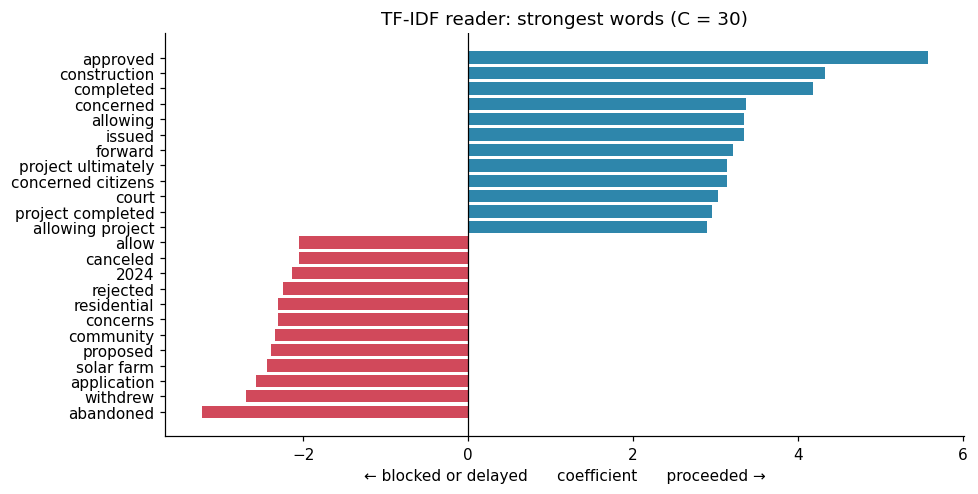

In [13]:
g = GridSearchCV(TFIDF, TFIDF_GRID, cv=CV, scoring="roc_auc").fit(silver["text"], silver["y"])
vocab = g.best_estimator_[0].get_feature_names_out()
coef = pd.Series(g.best_estimator_[-1].coef_[0], index=vocab).sort_values()
fig, ax = plt.subplots(figsize=(9, 4.6))
top = pd.concat([coef.head(12), coef.tail(12)])
ax.barh(top.index, top.values, color=np.where(top.values > 0, "#2e86ab", "#d1495b"))
ax.axvline(0, color="black", lw=0.8)
ax.set_title(f"TF-IDF reader: strongest words (C = {g.best_params_['logisticregression__C']})")
ax.set_xlabel("← blocked or delayed      coefficient      proceeded →")
fig.tight_layout()
plt.show()

The top words are the same outcome verbs the keyword rules use (*approved*, *operational*, *denied*, *withdrew*), plus context the rules miss, such as *lawsuit* and *appeal* for delayed projects. That's both its strength and its limit: TF-IDF doesn't know *who* did what. "Residents **appealed** the approval" and "the developer **appealed** the denial" look almost the same to it.

### General English: frozen transformers + logistic regression

A transformer reads each word in context (Lecture 11). The cheapest way to use one is **frozen**: run each paragraph through a pre-trained model once, average its output vectors into one embedding per paragraph, and fit a logistic regression on the embeddings (Lecture 12's "general English" reader). We try two encoders:

- **DistilBERT** (`distilbert-base-uncased`, 66M parameters), the model Lecture 12 fine-tunes.
- **MiniLM** (`all-MiniLM-L6-v2`, 22M parameters), a small model trained specifically to produce sentence embeddings for similarity search (the "embeddings support retrieval" idea from Lecture 14).

Paragraphs longer than `MAX_LEN` tokens are cut from the **left**, which keeps the ending.

In [14]:
def embed(texts, name, max_len=MAX_LEN, batch=32):
    """Mean-pooled last-layer embeddings, one row per text (no gradients: the encoder is frozen)."""
    tok = AutoTokenizer.from_pretrained(name, truncation_side="left")
    enc = AutoModel.from_pretrained(name).to(DEVICE).eval()
    out = []
    with torch.no_grad():
        for i in range(0, len(texts), batch):
            b = tok(list(texts[i:i + batch]), truncation=True, max_length=max_len, padding=True,
                    return_tensors="pt").to(DEVICE)
            h = enc(**b).last_hidden_state
            m = b["attention_mask"].unsqueeze(-1).float()
            out.append(((h * m).sum(1) / m.sum(1)).cpu().numpy())
    return np.vstack(out)

t0 = time.time()
EMB = {n: pd.DataFrame(embed(paras["text"].tolist(), m), index=paras.index)
       for n, m in [("DistilBERT", BERT), ("MiniLM", MINILM)]}
print({n: e.shape for n, e in EMB.items()}, f"({time.time() - t0:.0f}s)")

{'DistilBERT': (572, 768), 'MiniLM': (572, 384)} (25s)


In [15]:
FROZEN = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=5000))
FROZEN_GRID = {"logisticregression__C": [0.001, 0.003, 0.01, 0.03, 0.1]}

def frozen(encoder):
    def fit_predict(train, test):
        inner = StratifiedKFold(5, shuffle=True, random_state=SEED)
        g = GridSearchCV(FROZEN, FROZEN_GRID, cv=inner, scoring="roc_auc")
        g.fit(EMB[encoder].loc[train.index], train["y"])
        return g.predict_proba(EMB[encoder].loc[test.index])[:, 1]
    return fit_predict

run("Frozen DistilBERT + logistic regression", frozen("DistilBERT"))
run("Frozen MiniLM + logistic regression", frozen("MiniLM"))

Frozen DistilBERT + logistic regression CV AUC 0.785   macro-F1 0.706   (9s)
Frozen MiniLM + logistic regression    CV AUC 0.698   macro-F1 0.647   (4s)


### Domain English: fine-tuned DistilBERT

Fine-tuning updates **all** of DistilBERT's weights on our task, with a classification head on top (Lecture 12). With only ~340 training paragraphs per fold, the course's recipe matters:

- **A small learning rate** (2e-5) with a short warm-up, so the pre-trained knowledge isn't overwritten.
- **Few epochs, with early stopping** (Lecture 9). A **validation set** (15% of the training paragraphs) is held out of each fit, and we keep the epoch with the lowest validation loss. Deep models use a validation set, not cross-validation, to decide when to stop.
- **Class-weighted loss** for the 2:1 imbalance (Lecture 11).
- **Several seeds, averaged.** On data this small the result depends on the random initialization of the head and the batch order, so we average `N_SEEDS` fine-tuned models.

In [16]:
def finetune(train, seed, lr=2e-5, batch=16, patience=2):
    """Fine-tune DistilBERT on `train`, early-stopped on a 15% validation split. Returns (tokenizer, model)."""
    torch.manual_seed(seed); np.random.seed(seed)
    fit, val = train_test_split(train, test_size=0.15, stratify=train["y"], random_state=seed)
    tok = AutoTokenizer.from_pretrained(BERT, truncation_side="left")
    model = AutoModelForSequenceClassification.from_pretrained(BERT, num_labels=2).to(DEVICE)
    w = len(fit) / (2 * np.bincount(fit["y"], minlength=2))
    loss_fn = torch.nn.CrossEntropyLoss(weight=torch.tensor(w, dtype=torch.float, device=DEVICE))
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    steps = EPOCHS * int(np.ceil(len(fit) / batch))
    sched = get_linear_schedule_with_warmup(opt, int(0.1 * steps), steps)

    def batches(df, shuffle):
        order = np.random.permutation(len(df)) if shuffle else np.arange(len(df))
        for i in range(0, len(df), batch):
            b = df.iloc[order[i:i + batch]]
            enc = tok(b["text"].tolist(), truncation=True, max_length=MAX_LEN, padding=True, return_tensors="pt")
            yield enc.to(DEVICE), torch.tensor(b["y"].to_numpy(), device=DEVICE)

    best, best_state, bad = np.inf, None, 0
    for epoch in range(EPOCHS):
        model.train()
        for enc, yb in batches(fit, shuffle=True):
            loss = loss_fn(model(**enc).logits, yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step(); sched.step(); opt.zero_grad()
        model.eval()
        with torch.no_grad():
            v = sum(loss_fn(model(**enc).logits, yb).item() * len(yb) for enc, yb in batches(val, False)) / len(val)
        if v < best:
            best, bad = v, 0
            best_state = {k: t.detach().cpu().clone() for k, t in model.state_dict().items()}
        else:
            bad += 1
            if bad >= patience:
                break
    model.load_state_dict(best_state)
    return tok, model.eval()


def bert_predict(tok, model, texts, batch=32):
    out = []
    with torch.no_grad():
        for i in range(0, len(texts), batch):
            enc = tok(list(texts[i:i + batch]), truncation=True, max_length=MAX_LEN, padding=True,
                      return_tensors="pt").to(DEVICE)
            out.append(torch.softmax(model(**enc).logits, -1)[:, 1].cpu().numpy())
    return np.concatenate(out)


def finetuned(train, test):
    """Average of N_SEEDS fine-tuned models."""
    ps = []
    for s in range(N_SEEDS):
        tok, model = finetune(train, seed=SEED + s)
        ps.append(bert_predict(tok, model, test["text"].tolist()))
        del model
        if DEVICE == "cuda":
            torch.cuda.empty_cache()
    return np.mean(ps, axis=0)

run("Fine-tuned DistilBERT", finetuned)

Fine-tuned DistilBERT                  CV AUC 0.916   macro-F1 0.810   (1014s)


### Comparing the readers on cross-validation

All numbers below come from the training paragraphs only, with each paragraph scored by a model that never saw it. The reader with the best CV AUC is **selected** here, before anyone looks at the test set.

In [17]:
cv_table = pd.DataFrame(cv_results).T
cv_table.index.name = "reader (5-fold CV on silver)"
BEST = cv_table.drop(index="Majority class (blocked/delayed)")["AUC"].idxmax()
print("Selected reader:", BEST)
cv_table

Selected reader: Fine-tuned DistilBERT


,AUC,macro-F1,recall blocked/delayed,recall proceeded
reader (5-fold CV on silver),,,,
Majority class (blocked/delayed),0.500,0.407,1.000,0.000
Keyword rules,0.802,0.681,0.620,0.842
TF-IDF + logistic regression,0.815,0.706,0.856,0.541
Frozen DistilBERT + logistic regression,0.785,0.706,0.747,0.699
Frozen MiniLM + logistic regression,0.698,0.647,0.726,0.586
Fine-tuned DistilBERT,0.916,0.810,0.873,0.752


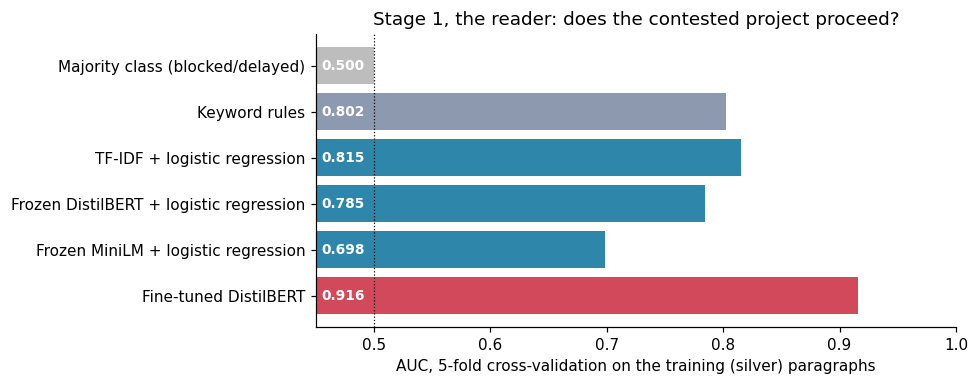

In [18]:
names = list(cv_table.index)
colors = ["#bdbdbd", "#8d99ae"] + ["#2e86ab"] * (len(names) - 2)
colors = [("#d1495b" if n == BEST else c) for n, c in zip(names, colors)]
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.barh(names[::-1], cv_table["AUC"][::-1], color=colors[::-1])
for i, v in enumerate(cv_table["AUC"][::-1]):
    ax.text(0.455, i, f"{v:.3f}", va="center", fontsize=9, color="white", fontweight="bold")
ax.axvline(0.5, color="black", lw=0.8, ls=":")
ax.set_xlim(0.45, 1.0)
ax.set_xlabel("AUC, 5-fold cross-validation on the training (silver) paragraphs")
ax.set_title("Stage 1, the reader: does the contested project proceed?")
fig.tight_layout()
fig.savefig(FIG / "07_text_reader_ladder.png", bbox_inches="tight")
plt.show()

What to look for in the table:

- **Do the learned readers beat the keyword rules?** Lecture 10's test is whether a model beats the readily-accessible baseline. Here that baseline is strong, because outcome verbs carry most of the signal.
- **Frozen vs. fine-tuned.** On ~400 paragraphs, fine-tuning has little data to adapt with. If it beats the frozen encoders, context helps: who appealed, whether a vote came before or after a lawsuit.
- **Recall on blocked/delayed** is the costly miss. A reader with a good AUC but low recall here would wave through projects that opposition actually stopped.

### Showtime for the reader: the human-labeled test set

Every reader is now refitted on all training paragraphs and scored **once** on the gold set. The interval is a 95% bootstrap over test paragraphs; with ~90 of them, differences of a few points of AUC are within noise.

In [19]:
gold_p, rows = {}, {}
for name, fp in readers.items():
    gold_p[name] = fp(silver, gold)
    m = metrics(gold["y"], gold_p[name])
    lo, hi = boot_auc(gold["y"], gold_p[name]) if name != "Majority class (blocked/delayed)" else (0.5, 0.5)
    rows[name] = {**m, "AUC 95% CI": f"[{lo:.2f}, {hi:.2f}]"}
gold_table = pd.DataFrame(rows).T
gold_table.index.name = "reader (gold test, scored once)"
gold_table

,AUC,macro-F1,recall blocked/delayed,recall proceeded,AUC 95% CI
"reader (gold test, scored once)",,,,,
Majority class (blocked/delayed),0.5,0.404,1.0,0.0,"[0.50, 0.50]"
Keyword rules,0.754,0.646,0.607,0.759,"[0.64, 0.86]"
TF-IDF + logistic regression,0.84,0.746,0.885,0.586,"[0.75, 0.92]"
Frozen DistilBERT + logistic regression,0.882,0.789,0.836,0.759,"[0.81, 0.94]"
Frozen MiniLM + logistic regression,0.738,0.631,0.672,0.621,"[0.62, 0.84]"
Fine-tuned DistilBERT,0.962,0.87,0.934,0.793,"[0.92, 0.99]"


In [20]:
gain = bootstrap_gain(gold["y"].to_numpy(), gold_p["Keyword rules"], gold_p[BEST])
print(f"{BEST} vs. keyword rules on gold: AUC gain {gain[0]:+.3f}, "
      f"95% CI [{gain[1]:+.3f}, {gain[2]:+.3f}], positive in {gain[3]:.0%} of bootstrap draws")
if BEST != "TF-IDF + logistic regression":
    gain = bootstrap_gain(gold["y"].to_numpy(), gold_p["TF-IDF + logistic regression"], gold_p[BEST])
    print(f"{BEST} vs. TF-IDF on gold: AUC gain {gain[0]:+.3f}, 95% CI [{gain[1]:+.3f}, {gain[2]:+.3f}]")

Fine-tuned DistilBERT vs. keyword rules on gold: AUC gain +0.209, 95% CI [+0.094, +0.339], positive in 100% of bootstrap draws
Fine-tuned DistilBERT vs. TF-IDF on gold: AUC gain +0.120, 95% CI [+0.036, +0.210]


### Where the selected reader goes wrong

The binary label merges *blocked* and *delayed*. Splitting the gold paragraphs back into the three original labels shows which kind of paragraph the reader gets wrong:

In [21]:
gold_view = gold.assign(p=gold_p[BEST], predicted=np.where(gold_p[BEST] >= 0.5, "proceeded", "blocked/delayed"))
err = pd.crosstab(gold_view["outcome"], gold_view["predicted"], margins=True, margins_name="total")
err["share right"] = [((gold_view["outcome"] == o) & ((gold_view["predicted"] == "proceeded") == (o == "proceeded"))).sum()
                      / max((gold_view["outcome"] == o).sum(), 1) for o in err.index[:-1]] + [np.nan]
err

predicted,blocked/delayed,proceeded,total,share right
outcome,,,,
blocked,38,0,38,1.000
delayed,19,4,23,0.826
proceeded,6,23,29,0.793
total,63,27,90,NaN


We expect most errors among the **delayed** paragraphs. A project set back by a lawsuit, then re-filed, often sits between the classes, and it's also where the human labelers disagreed most.

To read the misclassified paragraphs, flip `SHOW_TEXT` below. **Clear this cell's output before committing**, because it prints the report's text.

In [22]:
SHOW_TEXT = False
wrong = gold_view[(gold_view["p"] >= 0.5) != (gold_view["y"] == 1)]
print(f"{len(wrong)} of {len(gold_view)} gold paragraphs misclassified at 0.5")
if SHOW_TEXT:
    for _, r in wrong.sort_values("p").iterrows():
        print(f"\n[{r['outcome']}, P(proceeded) = {r['p']:.2f}] {r['project']} ({r['state']})\n{r['text'][:800]}")
else:
    display(wrong[["state", "project", "outcome", "p"]].sort_values("p"))

10 of 90 gold paragraphs misclassified at 0.5


,state,project,outcome,p
110,IN,Grandview Solar Project,proceeded,0.102
87,IL,Ford Ridge Wind Farm,proceeded,0.333
485,VT,"Apple Hill Solar and Willow Road Solar, f/k/a ...",proceeded,0.364
114,IN,Jordan Creek Wind Energy Center,proceeded,0.377
85,IL,Belvidere Solar,proceeded,0.392
169,ME,New England Clean Energy Connect,proceeded,0.455
416,OR,Echanis Wind Farm,delayed,0.524
74,HI,Kahuku Na Pua Makani Wind Project,delayed,0.534
313,NY,Bliss Solar 1 Project,delayed,0.663
326,NY,Freepoint Solar,delayed,0.750


### Scoring all 572 paragraphs, out of fold

Stage 2 needs the reader's probability for **every** paragraph, including the unresolved ones and the gold set. As in Lecture 7's stacking, each paragraph's score has to come from a model that **never trained on it**. Otherwise stage 2 would see a too-good feature that won't exist for new paragraphs. We split all 572 into 5 folds, train the selected reader on the labeled paragraphs of the other four (silver and gold together, now that the reader is chosen) and score the held-out fold.

In [23]:
def crossfit(fit_predict, df=paras, k=5):
    out = pd.Series(np.nan, index=df.index)
    for fit_idx, pred_idx in KFold(k, shuffle=True, random_state=SEED).split(df):
        train = df.iloc[fit_idx]
        train = train[train["y"].notna()].assign(y=lambda d: d["y"].astype(int))
        out.iloc[pred_idx] = fit_predict(train, df.iloc[pred_idx])
    return out

t0 = time.time()
p_reader = crossfit(readers[BEST])
resolved = paras["y"].notna()
print(f"Out-of-fold AUC on all {resolved.sum()} resolved paragraphs: "
      f"{roc_auc_score(paras.loc[resolved, 'y'], p_reader[resolved]):.3f}  ({time.time() - t0:.0f}s)")
print(f"Unresolved paragraphs, mean P(proceeded): {p_reader[~resolved].mean():.2f}")

Out-of-fold AUC on all 515 resolved paragraphs: 0.938  (1208s)
Unresolved paragraphs, mean P(proceeded): 0.27


## Stage 2: from paragraphs to queue projects

Now the question the investor actually asks. A new solar project enters the queue in a county. **What does the opposition record say about its chances?**

We use the same projects and the same label as the tabular notebook: `data.built_within(raw, 5)`, which covers clean-energy projects in the six operators that report completion dates, labeled 1 if operating within 5 years of entry.

**Dating, the most important rule (Lecture 8: lags from the past only).** For a project entering in year *t*:

- An earlier paragraph about its county counts as **contested** if the dispute started before *t* (`first_year < t`).
- Its **outcome** (the reader's P(proceeded)) counts only if the last event it describes is also before *t* (`last_year < t`). Until then it's "contested, outcome not yet known". An investor in 2016 can't know that a dispute that began in 2015 ends in a denial in 2018.

`text.county_text_features` builds, per project:

| Columns | Meaning |
|---|---|
| `c_contested`, `c_recent3` | earlier contested projects in the county; those starting in the 3 years before entry |
| `c_known`, `c_pending` | of those, outcome known before entry / not yet |
| `c_blocked`, `c_proceeded` | expected counts from the reader's P (known outcomes only) |
| `c_same_tech` | earlier contested projects of the same technology (solar, wind, battery) |
| `c_concern_*` | how often each concern was raised (farmland, viewshed, wildlife…) |
| `s_contested`, `s_blocked`, `s_proceeded` | the same at the **state** level, a fallback where the county has no history |
| `emb_*` | the average MiniLM embedding of the county's earlier paragraphs, reduced to 5 dimensions |

`selftest.py` checks the dating rules on a hand-built example.

In [24]:
raw = data.load_raw_queue()
projects = data.built_within(raw, config.HORIZON)

Z = PCA(n_components=5, random_state=SEED).fit_transform(EMB["MiniLM"].to_numpy())  # unsupervised: no labels used
feats = text.county_text_features(projects, paras, p_reader.to_numpy(), emb=Z)
oracle = text.county_text_features(projects, paras, paras["y"].fillna(0.5).to_numpy())  # human/Claude labels, not the reader

D = projects[["project_id", "q_year", "fips", "state", "type_1"]].assign(y=projects["built"]).join(feats)
D["has_text"] = (D["c_contested"] > 0).astype(int)
D[["c_blocked_oracle", "c_proceeded_oracle"]] = oracle[["c_blocked", "c_proceeded"]].to_numpy()

windows = {"Training era 2005–2014": (2005, 2014), "Out-of-time 2015–2018": (2015, 2018),
           "Test 2019–2020 (held out)": (2019, 2020)}
pd.DataFrame({w: {"projects": D["q_year"].between(*r).sum(),
                  "built within 5y": D.loc[D["q_year"].between(*r), "y"].mean(),
                  "county has earlier contested project": D.loc[D["q_year"].between(*r), "has_text"].mean(),
                  "... with a known outcome": (D.loc[D["q_year"].between(*r), "c_known"] > 0).mean(),
                  "state has earlier contested project": (D.loc[D["q_year"].between(*r), "s_contested"] > 0).mean()}
              for w, r in windows.items()}).T

,projects,built within 5y,county has earlier contested project,... with a known outcome,state has earlier contested project
Training era 2005–2014,4029.0,0.111,0.047,0.011,0.614
Out-of-time 2015–2018,3490.0,0.088,0.099,0.074,0.852
Test 2019–2020 (held out),3184.0,0.037,0.101,0.079,0.966


**Coverage is the binding constraint.** Only about 1 project in 10 entering in 2015–2018 is in a county with an earlier contested project, and about 1 in 20 before 2015. For the other 90%, the county record says nothing, and a text-only model can only fall back on the state. That is why text alone can't rank most projects, and why the real test is the fusion with the tabular model.

Where the county does have history, is there a signal? Build rates within 5 years, 2010–2018 entries:

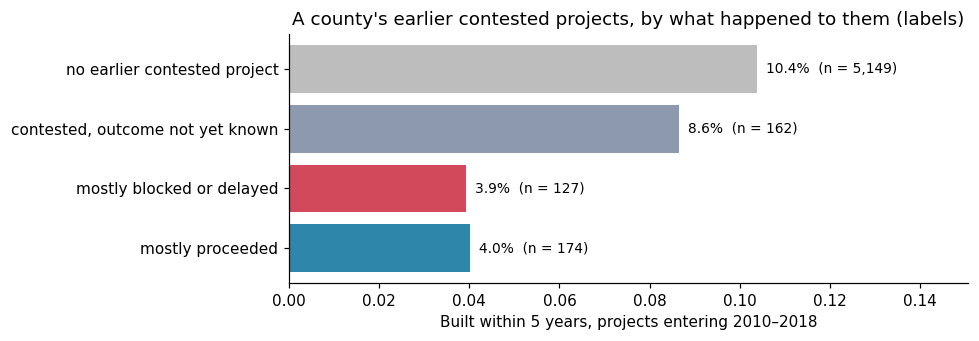

,projects,built
no earlier contested project,5149,0.104
"contested, outcome not yet known",162,0.086
mostly blocked or delayed,127,0.039
mostly proceeded,174,0.040


In [25]:
W = D[D["q_year"].between(2010, 2018)]
status = np.select([W["has_text"] == 0, W["c_known"] == 0, W["c_blocked_oracle"] >= W["c_proceeded_oracle"]],
                   ["no earlier contested project", "contested, outcome not yet known",
                    "mostly blocked or delayed"], "mostly proceeded")
order = ["no earlier contested project", "contested, outcome not yet known", "mostly blocked or delayed", "mostly proceeded"]
rate = W.groupby(status)["y"].agg(projects="size", built="mean").reindex(order)

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.barh(rate.index[::-1], rate["built"][::-1], color=["#2e86ab", "#d1495b", "#8d99ae", "#bdbdbd"])
for i, (b, n) in enumerate(zip(rate["built"][::-1], rate["projects"][::-1])):
    ax.text(b + 0.002, i, f"{b:.1%}  (n = {n:,})", va="center", fontsize=9)
ax.set_xlabel("Built within 5 years, projects entering 2010–2018")
ax.set_title("A county's earlier contested projects, by what happened to them (labels)")
ax.set_xlim(0, rate["built"].max() * 1.45)
fig.tight_layout()
fig.savefig(FIG / "08_text_build_rate_by_county_history.png", bbox_inches="tight")
plt.show()
rate

The pattern behind the stage-2 results:

- **Any earlier opposition in the county is bad news.** Projects entering where a contested project already played out are built within 5 years at well under half the rate of projects elsewhere. This is the signal `stack.py` found: odds of about ×0.55 even at the same tabular score, and lower on its own (printed below the stage-2 ladder).
- **Whether that earlier opposition *succeeded* barely matters**, at least at this sample size. The "mostly proceeded" and "mostly blocked" groups are each a few hundred projects with about a dozen builds between them, so we can't separate them. This answers HANDOFF thread #2 ("does successful opposition matter more than any opposition?"): not detectably. Read it as a correlation, not a cause. Counties that attract opposition may also be harder to build in for other reasons (Lecture 6).

### The stage-2 ladder

**Validation scheme.** We use **rolling origin**, as in the tabular notebook: for each year *t* from 2015 to 2018, fit on all entries before *t* and score year *t*. The model never sees the future. The score for each project is out of fold, which is what late fusion needs.

**Metric: AUC within each entry year, averaged.** The fund ranks projects *within* a cohort. Pooling years would mix in a trend: Sabin coverage rises over time while build rates fall, so a pooled AUC would partly reward predicting the year.

All models are logistic regressions on log(1 + count) features, standardized. We fix them in advance rather than tuning each one, since the signal is thin and tuning on four validation years would mostly fit noise.

In [26]:
COUNTS = ["c_contested", "c_recent3", "c_same_tech", "c_known", "c_pending"]
OUTCOMES = ["c_blocked", "c_proceeded"]
CONCERN_COLS = [f"c_concern_{k}" for k in text.CONCERNS]
STATE = ["s_contested", "s_blocked", "s_proceeded"]
EMB_COLS = [c for c in D.columns if c.startswith("emb_")]
LOG = COUNTS + OUTCOMES + CONCERN_COLS + STATE + ["c_blocked_oracle", "c_proceeded_oracle"]
X2 = D.copy()
X2[LOG] = np.log1p(X2[LOG])
X2["any_prior"] = D["has_text"]

LADDER = {   # name: (columns, penalty, C)
    "Flat rate": ([], None, None),
    "Any earlier contested project (today's flag)": (["any_prior"], "l2", 1.0),
    "Counts": (COUNTS, "l2", 1.0),
    "Counts + reader outcomes": (COUNTS + OUTCOMES, "l2", 1.0),
    "+ concerns (LASSO)": (COUNTS + OUTCOMES + CONCERN_COLS, "l1", 0.1),
    "+ state fallback": (COUNTS + OUTCOMES + STATE, "l2", 1.0),
    "+ mean paragraph embedding": (COUNTS + OUTCOMES + EMB_COLS, "l2", 1.0),
    "Oracle: labels instead of the reader": (COUNTS + ["c_blocked_oracle", "c_proceeded_oracle"], "l2", 1.0),
}
VAL_YEARS = [2015, 2016, 2017, 2018]


def stage2_model(penalty, C):
    return make_pipeline(StandardScaler(), LogisticRegression(penalty=penalty, C=C, solver="liblinear", max_iter=5000))


def rolling(cols, penalty, C, years=VAL_YEARS):
    """Each year t scored by a model fit on entries before t (out-of-fold, no look-ahead)."""
    p = pd.Series(np.nan, index=X2.index)
    for t in years:
        fit, held = X2["q_year"] < t, X2["q_year"] == t
        if not cols:
            p[held] = X2.loc[fit, "y"].mean()
        else:
            p[held] = stage2_model(penalty, C).fit(X2.loc[fit, cols], X2.loc[fit, "y"]).predict_proba(X2.loc[held, cols])[:, 1]
    return p


def by_year_auc(p, years=VAL_YEARS):
    return {t: roc_auc_score(X2.loc[X2["q_year"] == t, "y"], p[X2["q_year"] == t])
            if p[X2["q_year"] == t].nunique() > 1 else 0.5 for t in years}


s2_results, s2_oof = {}, {}
for name, (cols, pen, C) in LADDER.items():
    s2_oof[name] = rolling(cols, pen, C)
    yrs = by_year_auc(s2_oof[name])
    W = X2["q_year"].isin(VAL_YEARS)
    s2_results[name] = {"mean within-year AUC": np.mean(list(yrs.values())), **yrs,
                        "pooled AUC": roc_auc_score(X2.loc[W, "y"], s2_oof[name][W]) if cols else 0.5}
s2_table = pd.DataFrame(s2_results).T
s2_table.index.name = "stage 2, rolling origin 2015–2018"
s2_table

,mean within-year AUC,2015,2016,2017,2018,pooled AUC
"stage 2, rolling origin 2015–2018",,,,,,
Flat rate,0.500,0.500,0.500,0.500,0.500,0.500
Any earlier contested project (today's flag),0.525,0.558,0.521,0.512,0.510,0.558
Counts,0.526,0.558,0.523,0.512,0.510,0.558
Counts + reader outcomes,0.525,0.559,0.517,0.512,0.510,0.557
+ concerns (LASSO),0.524,0.559,0.525,0.511,0.503,0.559
+ state fallback,0.513,0.477,0.489,0.513,0.574,0.535
+ mean paragraph embedding,0.523,0.575,0.516,0.509,0.494,0.557
Oracle: labels instead of the reader,0.526,0.559,0.522,0.512,0.509,0.558


Selected stage-2 model: Counts


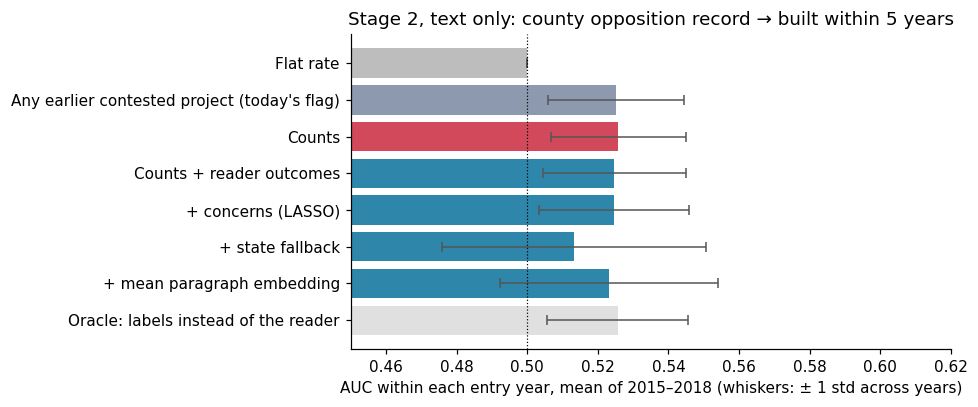

Odds of a 5-year build with an earlier contested project in the county: x0.44 (2005–2018 entries)


In [27]:
eligible = s2_table.drop(index=["Flat rate", "Oracle: labels instead of the reader"])
S2_BEST = eligible["mean within-year AUC"].idxmax()
print("Selected stage-2 model:", S2_BEST)

names2 = list(s2_table.index)
col2 = ["#bdbdbd", "#8d99ae"] + ["#2e86ab"] * (len(names2) - 3) + ["#e0e0e0"]
col2 = [("#d1495b" if n == S2_BEST else c) for n, c in zip(names2, col2)]
spread = [np.std([s2_table.loc[n, t] for t in VAL_YEARS]) for n in names2]
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.barh(names2[::-1], s2_table["mean within-year AUC"][::-1], xerr=spread[::-1], color=col2[::-1], capsize=3,
        error_kw={"ecolor": "#555555", "lw": 1})
ax.axvline(0.5, color="black", lw=0.8, ls=":")
ax.set_xlim(0.45, 0.62)
ax.set_xlabel("AUC within each entry year, mean of 2015–2018 (whiskers: ± 1 std across years)")
ax.set_title("Stage 2, text only: county opposition record → built within 5 years")
fig.tight_layout()
fig.savefig(FIG / "09_text_stage2_ladder.png", bbox_inches="tight")
plt.show()

m = stage2_model("l2", 1.0).fit(X2.loc[X2["q_year"] <= 2018, ["any_prior"]], X2.loc[X2["q_year"] <= 2018, "y"])
print(f"Odds of a 5-year build with an earlier contested project in the county: "
      f"x{np.exp(m[-1].coef_[0][0] / m[0].scale_[0]):.2f} (2005–2018 entries)")

**Reading the ladder:**

- **Text alone ranks weakly**, a few points above a coin flip within each year. That's expected when 90% of projects have no county record. It isn't the right yardstick for this model, though. Its job is to add information the tabular model doesn't have, which the fusion step will measure.
- **Most of the signal is in the simplest feature**, whether the county has seen a contested project before. Counting, dating, reader outcomes, concerns and embeddings add little or nothing on top. The **oracle** row is the ceiling: replacing the reader with the labels themselves barely moves it. So a better reader would not help stage 2, even though stage 1 shows the reader works.
- **The state fallback** gives every project a score, but it partly measures *which state*, and the tabular model already knows that. Late fusion will tell us whether it adds anything.

### Export for late fusion

`data/processed/text_scores.csv` holds one row per 2015–2018 project. `p_text` is the selected stage-2 model's rolling out-of-fold score, `has_text` flags the ~10% with a county record, and the features are included so the fusion step can try them. Join on `project_id` to the tabular model's out-of-time scores. Both models then score every project with nothing fit on that project's year or later, which is what a fair late fusion needs (Lecture 7).

In [28]:
W = X2["q_year"].isin(VAL_YEARS)
scores = (D.loc[W, ["project_id", "q_year", "y", "has_text"]]
          .assign(p_text=s2_oof[S2_BEST][W], model=S2_BEST, split="rolling 2015-2018")
          .join(feats.loc[W]))
path = text.write_text_scores(scores)
print(f"Wrote {len(scores):,} rows to {path.relative_to(config.ROOT)}; "
      f"p_text missing: {scores['p_text'].isna().sum()}; has_text: {scores['has_text'].mean():.0%}")
if IN_COLAB:
    from google.colab import files
    files.download(str(path))      # copy it into data/processed/ on your laptop

Wrote 3,490 rows to data/processed/text_scores.csv; p_text missing: 0; has_text: 10%


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Showtime: the held-out test cohort (not run)

As in the tabular notebook, the 2019–2020 cohort is scored **once**, after the team agrees on the final setup. The switch below stays `False` until then. Following `stack.py --final`, the selected stage-2 model is fit on 2005–2018 entries and scores 2019–2020. Strictly, a fund deciding in 2019 wouldn't know the 2015–2018 outcomes yet, so that choice should be made together with the tabular test run.

In [29]:
RUN_FINAL = False   # The team agrees first (docs/HANDOFF.md). Do not flip this alone.

test = X2["q_year"].between(*config.TEST_YEARS)
if RUN_FINAL:
    cols, pen, C = LADDER[S2_BEST]
    fit = X2["q_year"] <= 2018
    p_test = stage2_model(pen, C).fit(X2.loc[fit, cols], X2.loc[fit, "y"]).predict_proba(X2.loc[test, cols])[:, 1]
    p_test = pd.Series(p_test, index=X2.index[test])
    print("Test AUC by year:", {t: round(roc_auc_score(X2.loc[test & (X2['q_year'] == t), 'y'],
                                                       p_test[X2.loc[test, 'q_year'] == t]), 3)
                                for t in range(config.TEST_YEARS[0], config.TEST_YEARS[1] + 1)})
else:
    print(f"Test cohort ({config.TEST_YEARS[0]}–{config.TEST_YEARS[1]}, {test.sum():,} projects) not scored.")

Test cohort (2019–2020, 3,184 projects) not scored.


## Summary

In [30]:
r = cv_table.loc[BEST]
g = gold_table.loc[BEST]
kw = gold_table.loc["Keyword rules"]
s2 = s2_table.loc[S2_BEST]
flag = s2_table.loc["Any earlier contested project (today's flag)"]
cov = D.loc[D["q_year"].isin(VAL_YEARS), "has_text"].mean()
display(Markdown(f"""
| Question | What the text-only model shows |
|---|---|
| **Can a model read the outcome of a dispute?** | Yes. The selected reader (**{BEST}**) has CV AUC {r['AUC']:.3f} on Claude's labels and **{g['AUC']:.3f}** {g['AUC 95% CI']} on the human-labeled test set, against {kw['AUC']:.3f} for keyword rules. It catches {g['recall blocked/delayed']:.0%} of blocked or delayed projects at a 0.5 threshold |
| **Does the county's record predict a new project?** | Weakly, on its own. Mean within-year AUC is **{s2['mean within-year AUC']:.3f}** for the selected model (*{S2_BEST}*) and {flag['mean within-year AUC']:.3f} for the simple "earlier contested project" flag, on 2015–2018 entries |
| **Why so weak?** | Coverage: only **{cov:.0%}** of 2015–2018 projects are in a county with an earlier contested project. Where there is one, 5-year build rates are less than half those elsewhere |
| **Does *successful* opposition matter more?** | Not detectably. Using the labels themselves instead of the reader (the oracle row) adds nothing over counting disputes |
| **What goes to the fusion step?** | `data/processed/text_scores.csv`: out-of-fold `p_text` for every 2015–2018 project, plus the features |
"""))


| Question | What the text-only model shows |
|---|---|
| **Can a model read the outcome of a dispute?** | Yes. The selected reader (**Fine-tuned DistilBERT**) has CV AUC 0.916 on Claude's labels and **0.962** [0.92, 0.99] on the human-labeled test set, against 0.754 for keyword rules. It catches 93% of blocked or delayed projects at a 0.5 threshold |
| **Does the county's record predict a new project?** | Weakly, on its own. Mean within-year AUC is **0.526** for the selected model (*Counts*) and 0.525 for the simple "earlier contested project" flag, on 2015–2018 entries |
| **Why so weak?** | Coverage: only **10%** of 2015–2018 projects are in a county with an earlier contested project. Where there is one, 5-year build rates are less than half those elsewhere |
| **Does *successful* opposition matter more?** | Not detectably. Using the labels themselves instead of the reader (the oracle row) adds nothing over counting disputes |
| **What goes to the fusion step?** | `data/processed/text_scores.csv`: out-of-fold `p_text` for every 2015–2018 project, plus the features |


**Caveats to keep in the pitch:**

1. **Selection.** Sabin lists projects that drew *notable* opposition and were written up. Quiet counties and unreported fights look the same: no record.
2. **Silver labels.** Claude labeled 82% of the paragraphs. The human test set checks that the reader agrees with people, but the training labels carry Claude's judgment calls. The open team questions are whether "pending with opposition" counts as *delayed*, and the four disputed paragraphs that use Claude's suggested rulings.
3. **Dating is approximate.** `last_year` is the latest year a paragraph mentions, which stands in for when the outcome became public. A paragraph that mentions a future date ("expected online in 2027") is conservatively treated as not yet known.
4. **Thin before 2015.** The reports start in 2021 and look back selectively, so the text signal is mostly about recent cohorts. That's a good fit for the test years but leaves little to train on.
5. **Association, not cause.** Earlier opposition marks counties where projects struggle. It doesn't show that the opposition is the reason.

**Next:** late fusion. Join `text_scores.csv` to the tabular model's out-of-time scores, and combine them with a logistic regression on the two log-odds, fit leave-one-year-out (`stack.py`'s design). Then compare with tabular alone, using the bootstrap AUC gain.